# Statistical investigation: did discounting pay for itself?

**Business question.** Discount codes (10-25% off) are used on about one order in five. Marketing believes they drive sales. Did they increase sales enough to justify the margin they give away?

**What 'paying for itself' would require.** A discount reduces the profit of every order that uses it. To break even, discounted orders would need to be *bigger* (more items, higher basket), or the customers would need to *come back more often*. Both are testable.

**Plan.**
1. Describe discounted vs full-price orders.
2. Check for confounding (when are codes used?).
3. Compare basket size within the same month, with confidence intervals.
4. Compare repeat purchasing, stratified by month.
5. Break-even arithmetic.
6. Conclusion, assumptions and limitations.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import db

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.figsize": (9, 3.2), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b9b8b3"
conn = db.connect()
sql = lambda q: db.query(conn, q)
from scipy import stats
import discount_analysis as da

## 1. Describe

In [2]:
o, f = da.load(conn)
o.groupby("disc")[["units", "basket", "net_revenue", "gross_profit"]].agg(["mean", "median", "count"]).T

disc                     False     True 
units        mean         3.17      3.18
             median       3.00      3.00
             count  108,668.00 28,254.00
basket       mean       170.22    170.95
             median     131.97    131.98
             count  108,668.00 28,254.00
net_revenue  mean       164.98    142.05
             median     127.99    109.53
             count  108,668.00 28,254.00
gross_profit mean        67.79     44.56
             median      51.60     32.91
             count  108,668.00 28,254.00

At first sight discounted orders have the same basket but much lower profit. Before believing it, check whether the two groups are comparable.

## 2. Confounding: codes are not used at random

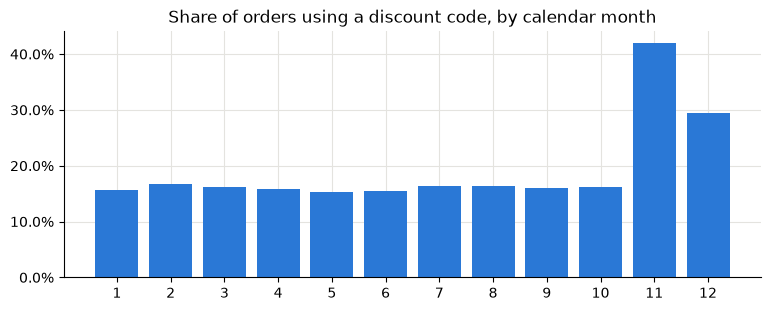

In [3]:
share = o.groupby(o["month"].dt.month)["disc"].mean()
fig, ax = plt.subplots()
ax.bar(share.index, share.values, color=BLUE)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_xticks(range(1, 13))
ax.set_title("Share of orders using a discount code, by calendar month"); plt.show()

Codes are used about twice as often in November and December, when baskets are different (gifts, Black Friday). Comparing all discounted orders with all full-price orders would mix the discount effect with the season. So every comparison below is made **within the same month** and then averaged, weighted by the number of discounted orders.

## 3. Basket size: within-month difference with a bootstrap confidence interval

In [4]:
res = da.analyse(o, f)
pd.DataFrame({k: res[k] for k in ("units", "basket", "gross_profit")}).T[["diff", "lo", "hi", "months_higher", "months"]]

,diff,lo,hi,months_higher,months
units,0.01,-0.02,0.03,15.00,24.00
basket,0.97,-0.67,2.78,11.00,24.00
gross_profit,-23.27,-24.09,-22.48,0.00,24.00


In [5]:
print("Mann-Whitney U, units per order: p =", round(res["p_units"], 3))
print("Welch t-test, basket before discount: t = %.2f, p = %.3f" % (res["t_basket"], res["p_basket"]))
print("Welch t-test, gross profit per order: t = %.1f, p = %.2g" % (res["t_gp"], res["p_gp"]))

Mann-Whitney U, units per order: p = 0.687
Welch t-test, basket before discount: t = 0.74, p = 0.457
Welch t-test, gross profit per order: t = -56.3, p = 0


The confidence intervals for units per order and basket value both include zero: there is no evidence that a code makes customers buy more. Gross profit per order is lower in every one of the 24 months. Order values are skewed, so the t-test on the basket is backed up by a rank-based test and bootstrap intervals (with this many orders the sample means are close to normal anyway).

## 4. Do discounted first orders create loyal customers?

If codes brought in customers who then came back, the lost margin could be an acquisition cost worth paying. Compare the 90-day repeat rate of first-time buyers with and without a code, again stratified by month (Cochran-Mantel-Haenszel).

In [6]:
rep = res["repeat"]
print(f"90-day repeat: full price {rep['rate_full_price']:.1%}, discounted {rep['rate_discounted']:.1%}")
print(f"common odds ratio {rep['odds_ratio']:.2f} (95% CI {rep['lo']:.2f} to {rep['hi']:.2f}), CMH chi2 = {rep['chi2']:.1f}, p = {rep['p']:.3f}")

90-day repeat: full price 32.6%, discounted 31.0%
common odds ratio 0.96 (95% CI 0.92 to 1.00), CMH chi2 = 3.1, p = 0.076


The odds ratio is slightly *below* 1 and its confidence interval reaches 1: discounted first-time buyers are not more likely to return, if anything a little less.

## 5. Break-even

In [7]:
m = res["margin_full"]
pd.DataFrame({"discount": list(res["break_even_lift"]),
              "basket increase needed to keep the same profit": [f"{v:.0%}" for v in res["break_even_lift"].values()]})

,discount,basket increase needed to keep the same profit
0,0.10,32%
1,0.15,57%
2,0.20,95%
3,0.25,155%


In [8]:
print(f"Observed basket difference: {res['basket']['diff'] / res['mean'].loc[False, 'basket']:+.1%}")
print(f"Gross profit given away vs the same orders at full price: EUR {res['profit_given_away']:,.0f}")

Observed basket difference: +0.6%
Gross profit given away vs the same orders at full price: EUR 656,346


## 6. Conclusion

**No: in this data, discount codes did not pay for themselves.** Discounted baskets are the same size as full-price ones, customers who start with a code are no more loyal, and the codes cost the margin shown above.

**Recommendation.** Stop blanket codes. Test targeted offers (for example on overstocked products, or a second-order incentive) against a randomised hold-out group before rolling them out.

**Assumptions and limitations.**
- Observational data: customers chose to use a code. Only a randomised hold-out measures true incrementality.
- Orders only, no website sessions: if a code persuades someone to buy *at all*, that conversion effect is invisible here, so the cost above is an upper bound.
- Month stratification removes seasonality, but not every possible difference between code users and other customers.